<a href="https://colab.research.google.com/github/Deepeshyadav061205/Small_Language_model_01/blob/main/small_language_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
# ---------- 1. Setup and GPU check ----------
!pip install -q datasets tokenizers matplotlib

import os, re, math, time, random
from collections import Counter
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
torch.manual_seed(42)
random.seed(42)


Device: cpu


In [15]:
# ---------- 2. Load dataset ----------
from datasets import load_dataset

ds = load_dataset("roneneldan/TinyStories", split="train")
texts = ds.shuffle(seed=42).select(range(20_000))["text"]
print("Number of stories:", len(texts))

Number of stories: 20000


In [16]:
# ---------- 3. Train BPE tokenizer ----------
from tokenizers import ByteLevelBPETokenizer

EOS_TOKEN = "<|endoftext|>"
VOCAB_SIZE = 8000

tokenizer = ByteLevelBPETokenizer()
tokenizer.train_from_iterator(
    texts, vocab_size=VOCAB_SIZE, min_frequency=2, special_tokens=[EOS_TOKEN]
)
os.makedirs("tinystories_tokenizer", exist_ok=True)
tokenizer.save_model("tinystories_tokenizer")
eos_id = tokenizer.token_to_id(EOS_TOKEN)
print("Vocab size:", tokenizer.get_vocab_size(), "| EOS id:", eos_id)

Vocab size: 8000 | EOS id: 0


In [17]:
STOP = set("""the a an and of to in on at with for was were is are he she it they
his her their them that this there then so but as be had has have not one day
upon time named little big very who what when where which all out up down into
its our we you your my me him""".split())

doc_freq = Counter()
for s in texts:
    doc_freq.update(set(re.findall(r"[a-z]+", s.lower())))

def make_topic(story, k=3):
    words = set(re.findall(r"[a-z]+", story.lower()))
    cands = sorted(w for w in words
                   if w not in STOP and len(w) > 3 and 20 <= doc_freq[w] <= 5000)
    return random.sample(cands, min(k, len(cands)))

examples = [f"Topic: {', '.join(make_topic(s))}\nStory: {s}" for s in texts]
print(examples[0][:300])


Topic: drops, balance, just
Story: Tim and Mia like to play in the park. They see a big club on the ground. It is brown and long and heavy.

"Look, a club!" Tim says. "I can lift it!"

He tries to lift the club, but it is too tough. He falls down and drops the club.

"Ouch!" he says. "That hurt!"

M


In [18]:
# ---------- 5. Convert to token tensors ----------
ids = []
for enc in tokenizer.encode_batch(examples):
    ids.extend(enc.ids)
    ids.append(eos_id)

data = torch.tensor(ids, dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
print("Total tokens:", len(data), "| Train:", len(train_data), "| Val:", len(val_data))


Total tokens: 4634428 | Train: 4170985 | Val: 463443


In [19]:
# ---------- 6. GPT model ----------
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, dropout):
        super().__init__()
        self.n_head = n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        y = F.scaled_dot_product_attention(
            q, k, v, is_causal=True,
            dropout_p=self.dropout if self.training else 0.0,
        )
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.proj(y))

class MLP(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd), nn.GELU(),
            nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.mlp = MLP(n_embd, dropout)
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

class GPT(nn.Module):
    def __init__(self, vocab_size, block_size, n_layer, n_head, n_embd, dropout):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))
        x = self.ln_f(self.blocks(x))
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=40, stop_id=None):
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.block_size:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = -float("inf")
            next_id = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat((idx, next_id), dim=1)
            if stop_id is not None and next_id.item() == stop_id:
                break
        return idx

In [22]:
# ---------- 7. Config and training ----------
block_size = 256
batch_size = 16        # was 32
max_iters = 500        # was 2000
eval_interval = 250    # was 500
eval_iters = 5         # was 10
warmup_iters = 50      # was 100 (scaled down with max_iters)
max_lr = 1e-3
min_lr = 1e-4

config = dict(
    vocab_size=VOCAB_SIZE,
    block_size=block_size,
    n_layer=2,         # was 4
    n_head=2,          # was 4
    n_embd=128,        # was 256
    dropout=0.1,
)

def get_batch(split):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - block_size - 1, (batch_size,))
    x = torch.stack([d[i : i + block_size] for i in ix])
    y = torch.stack([d[i + 1 : i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

def get_lr(it):
    if it < warmup_iters:
        return max_lr * (it + 1) / warmup_iters
    progress = (it - warmup_iters) / (max_iters - warmup_iters)
    return min_lr + 0.5 * (max_lr - min_lr) * (1 + math.cos(math.pi * progress))

@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            xb, yb = get_batch(split)
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
                _, loss = model(xb, yb)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

model = GPT(**config).to(device)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")

optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr, weight_decay=0.1)
scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

history = {"step": [], "train": [], "val": []}
start = time.time()
model.train()

for it in range(max_iters):
    lr = get_lr(it)
    for group in optimizer.param_groups:
        group["lr"] = lr

    if it % eval_interval == 0 or it == max_iters - 1:
        losses = estimate_loss()
        history["step"].append(it)
        history["train"].append(losses["train"])
        history["val"].append(losses["val"])
        print(f"step {it:5d} | train {losses['train']:.4f} | "
              f"val {losses['val']:.4f} | {time.time()-start:.0f}s")

    xb, yb = get_batch("train")
    with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
        _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(optimizer)
    scaler.update()

print("Training finished in", round(time.time() - start), "seconds")
torch.save({"model_state": model.state_dict(), "config": config}, "slm_topic_stories.pt")
print("Saved slm_topic_stories.pt")

Model parameters: 1.45M
step     0 | train 9.0004 | val 8.9962 | 3s
step   250 | train 4.0414 | val 3.9753 | 301s
step   499 | train 3.7683 | val 3.7930 | 592s
Training finished in 593 seconds
Saved slm_topic_stories.pt


In [23]:
# ---------- 8. Generate stories from a topic ----------
@torch.no_grad()
def story_about(topic_words, max_new_tokens=250, temperature=0.8, top_k=40):
    model.eval()
    words = [w.strip().lower() for w in topic_words.split(",") if w.strip()]
    for w in words:
        if len(tokenizer.encode(" " + w).tokens) > 1:
            print(f"Note: '{w}' is split into several tokens and may be ignored.")
    prompt = f"Topic: {', '.join(words)}\nStory:"
    ids_in = torch.tensor([tokenizer.encode(prompt).ids], dtype=torch.long, device=device)
    out = model.generate(ids_in, max_new_tokens=max_new_tokens,
                         temperature=temperature, top_k=top_k, stop_id=eos_id)
    return tokenizer.decode(out[0].tolist()).split("Story:", 1)[-1].strip()

for topic in ["dog, park, ball", "rain, umbrella, friend", "dragon, cave, gold"]:
    print("TOPIC:", topic)
    print(story_about(topic))
    print("-" * 60)


TOPIC: dog, park, ball
Lily went to play together. Lily. Lily loved to see that and Tom asked a big, Lily. They were the park. They are not like the bird named Tom and Ben.



Tim and Ben and Tom like the ball.


They put the tree and Ben.
 They are not like the door and Tim and Lily and they found a little girl named Lily. They like a special. They decided to the park. They found many old and Ben were happy. They are not know what she was sad. They said, but they all the park. They ran to find fun with it. He had a big things and Ben learned that day, they not like to play in the kitchen and run to the grass. They are not see that they both for her mom and it inside in the ball to the little girl. They laughed. They had to their new mom. They learned a good.



"Thank you have a toy, "You want to help me. 

They put the box and happy again. They were very happy. They were all the sky and Dad and Ben. They played with their mom and they saw their toys and Ben said. They do not nice and

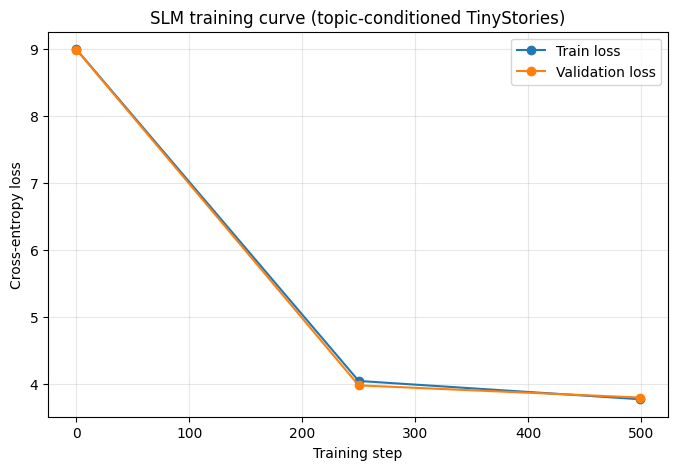

In [24]:
# ---------- 9. Plot loss curve ----------
plt.figure(figsize=(8, 5))
plt.plot(history["step"], history["train"], label="Train loss", marker="o")
plt.plot(history["step"], history["val"], label="Validation loss", marker="o")
plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("SLM training curve (topic-conditioned TinyStories)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig("loss_curve.png", dpi=150)
plt.show()


In [25]:
import shutil
from google.colab import files

shutil.make_archive("slm_model_package", "zip", root_dir=".",
                    base_dir=None)
# Include only the files needed to reload the model
shutil.rmtree("package", ignore_errors=True)
import os
os.makedirs("package", exist_ok=True)
shutil.copy("slm_topic_stories.pt", "package/")
shutil.copytree("tinystories_tokenizer", "package/tinystories_tokenizer")
shutil.copy("loss_curve.png", "package/")

shutil.make_archive("slm_model_package", "zip", root_dir="package")
files.download("slm_model_package.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>